# TP — Génération de texte avec LSTM (PyTorch)

**Objectif :** entraîner un modèle de langage caractère-par-caractère (Embedding + LSTM) pour générer du texte à partir d'un corpus.

ETAPES :
1. Préparer les données
2. Implémenter un modèle LSTM en PyTorch.
3. Entraîner le modèle avec `CrossEntropyLoss`.
4. Générer du texte avec un contrôle de température.
5. Sauvegarder/charger le modèle pour réutiliser l'entraînement.
6. Tester en changeant les params

## 0. Préliminaires

- Bibliothèques nécessaires : `torch`, `matplotlib`, `numpy`
- Données : fichier `voltaire_clean.txt`

In [24]:
import os, json, random, time
from dataclasses import dataclass

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, Subset

# Reproductibilité
SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def get_device():
    if torch.cuda.is_available():
        name = torch.cuda.get_device_name(0)
        return torch.device("cuda"), f"cuda ({name})"
    return torch.device("cpu"), "cpu"

device, device_name = get_device()
print(f"Device: {device} — {device_name}")

Device: cuda — cuda (Tesla T4)


## 1. Chargement du corpus texte

Fichier `voltaire_clean.txt`

In [25]:
# Téléchargement
!git clone https://github.com/nzmonzmp/dataset-voltaire.git
!cp dataset-voltaire/voltaire_clean.txt .

fatal: destination path 'dataset-voltaire' already exists and is not an empty directory.


In [26]:
TEXT_PATH = 'voltaire_clean.txt'

# Extrait Original
candide_excerpt = """ Dans le château de Thunder-ten-tronckh, en Westphalie, vivait un jeune garçon à qui la nature avait donné les mœurs les plus douces.
Sa physionomie annonçait son âme. Il avait le jugement assez droit, avec l'esprit le plus simple ; c'est, je crois, pour cette raison qu'on le nommait Candide.
Les anciens domestiques de la maison soupçonnaient qu'il était fils de la sœur de monsieur le baron, et d'un bon et honnête gentilhomme du voisinage,
que cette demoiselle ne voulut jamais épouser parce qu'il n'avait pu prouver que soixante et onze quartiers,
et que le reste de son arbre généalogique avait été perdu par l'injure du temps. """

if os.path.isfile(TEXT_PATH):
    with open(TEXT_PATH, 'r', encoding='utf-8') as f:
        text = f.read()
    print(f"Fichier chargé: {TEXT_PATH}")
else:
    print("Fichier non trouvé, utilisation d'un extrait de Candide.")
    text = candide_excerpt

print(f"Longueur du corpus: {len(text)} caractères")
print(f"Extrait: {text[:200]}...")

Fichier chargé: voltaire_clean.txt
Longueur du corpus: 816059 caractères
Extrait: Comment Candide fut élevé dans un beau château, et comment il fut chassé d'icelui. Il y avait en Vestphalie, dans le château de M. le baron de Thunder-ten-tronckh, un jeune garçon à qui la nature avai...


## 2. Pré-traitement : vocabulaire & encodage caractère

Construction du vocabulaire à partir des caractères observés et création des fonctions d'encodage/décodage.

### Exercice 1 — Vocabulaire & encodage

In [27]:
# Vocabulaire
chars = sorted(list(set(text)))
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

vocab_size = len(stoi)
print(f'Taille du vocabulaire: {vocab_size} caractères')

# Fonctions d'encodage/décodage
def encode(s: str):
    return [stoi[c] for c in s if c in stoi]

def decode(ids):
    return ''.join(itos[i] for i in ids)

# Test
test = "Bonjour"
print(f"Test: {test} -> {decode(encode(test))}")

# Encodage du corpus
encoded = torch.tensor(encode(text), dtype=torch.long)
print(f'Longueur encodée: {len(encoded)}')

Taille du vocabulaire: 100 caractères
Test: Bonjour -> Bonjour
Longueur encodée: 816059


## 3. Jeu de données & DataLoader

Création de séquences glissantes : chaque séquence d'entrée a pour cible la même séquence décalée d'une position.

### Exercice 2 — Dataset caractère & DataLoader

In [28]:
# Paramètres du modèle
@dataclass
class LMConfig:
    seq_len: int = 60
    batch_size: int = 128
    num_workers: int = 0
    drop_last: bool = True

cfg = LMConfig()

class CharDataset(Dataset):
    def __init__(self, encoded_tensor: torch.Tensor, seq_len: int):
        self.data = encoded_tensor
        self.seq_len = seq_len

    def __len__(self):
        return max(0, len(self.data) - self.seq_len - 1)

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_len]
        y = self.data[idx + 1 : idx + 1 + self.seq_len]
        return x, y

# Dataset complet
dataset = CharDataset(encoded, cfg.seq_len)

# Split train/val (90/10)
n = len(dataset)
n_train = int(0.9 * n)
n_val = n - n_train

indices = torch.randperm(n).tolist()
train_idx, val_idx = indices[:n_train], indices[n_train:]

train_ds = Subset(dataset, train_idx)
val_ds = Subset(dataset, val_idx)

# DataLoaders
train_dl = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                      num_workers=cfg.num_workers, drop_last=cfg.drop_last)
val_dl = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False,
                    num_workers=cfg.num_workers, drop_last=False)  # Ne pas drop pour validation

print(f"Taille train/val: {len(train_ds)}, {len(val_ds)}")
print(f"Batches train/val: {len(train_dl)}, {len(val_dl)}")

Taille train/val: 734398, 81600
Batches train/val: 5737, 638


## 4. Modèle LSTM (Embedding  LSTM  Linéaire)

Architecture du modèle :
- `nn.Embedding` : conversion des indices en vecteurs denses
- `nn.LSTM` : modélisation des dépendances séquentielles
- `nn.Linear` : prédiction de la distribution sur les caractères

In [29]:
class CharLSTM(nn.Module):
    def __init__(self, vocab_size: int, emb_dim: int = 128, hidden_dim: int = 256,
                 num_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, emb_dim)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                           batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden=None):
        x = self.embed(x)
        out, hidden = self.lstm(x, hidden)
        logits = self.fc(out)
        return logits, hidden

model = CharLSTM(
    vocab_size=vocab_size,
    emb_dim=64,
    hidden_dim=128,
    num_layers=1,
    dropout=0.2
).to(device)
print(model)

CharLSTM(
  (embed): Embedding(100, 64)
  (lstm): LSTM(64, 128, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=128, out_features=100, bias=True)
)


## 5. Entraînement

- **Perte** : `CrossEntropyLoss` appliquée pas de temps par pas de temps
- **Optimiseur** : `Adam`
- **Clipping** des gradients pour éviter l'explosion

### Exercice 3 — Boucle d'entraînement

In [30]:
EPOCHS = 20
LR = 3e-3
GRAD_CLIP = 1.0

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def iterate_epoch(dataloader, train=True):
    model.train(train)
    total_loss, steps = 0.0, 0
    for xb, yb in dataloader:
        xb = xb.to(device)
        yb = yb.to(device)

        logits, _ = model(xb)
        loss = criterion(logits.reshape(-1, vocab_size), yb.reshape(-1))

        if train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            if GRAD_CLIP is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()

        total_loss += loss.item()
        steps += 1
    return total_loss / max(steps, 1)

train_losses, val_losses = [], []
start = time.time()

for epoch in range(1, EPOCHS+1):
    tr = iterate_epoch(train_dl, train=True)
    vl = iterate_epoch(val_dl, train=False)
    train_losses.append(tr)
    val_losses.append(vl)
    print(f"[Epoch {epoch:02d}] train={tr:.3f} | val={vl:.3f}")

elapsed = time.time() - start
print(f"\nEntraînement terminé en {elapsed:.1f}s")

[Epoch 01] train=1.490 | val=1.320
[Epoch 02] train=1.286 | val=1.263
[Epoch 03] train=1.250 | val=1.239
[Epoch 04] train=1.232 | val=1.227
[Epoch 05] train=1.222 | val=1.221
[Epoch 06] train=1.215 | val=1.213
[Epoch 07] train=1.210 | val=1.209
[Epoch 08] train=1.206 | val=1.206
[Epoch 09] train=1.203 | val=1.203
[Epoch 10] train=1.200 | val=1.201
[Epoch 11] train=1.198 | val=1.198
[Epoch 12] train=1.196 | val=1.198
[Epoch 13] train=1.195 | val=1.196
[Epoch 14] train=1.194 | val=1.195
[Epoch 15] train=1.193 | val=1.194
[Epoch 16] train=1.192 | val=1.195
[Epoch 17] train=1.191 | val=1.193
[Epoch 18] train=1.190 | val=1.193
[Epoch 19] train=1.190 | val=1.193
[Epoch 20] train=1.189 | val=1.191

Entraînement terminé en 571.8s


### Courbe de perte

### Exercice 4 — Visualisation des pertes

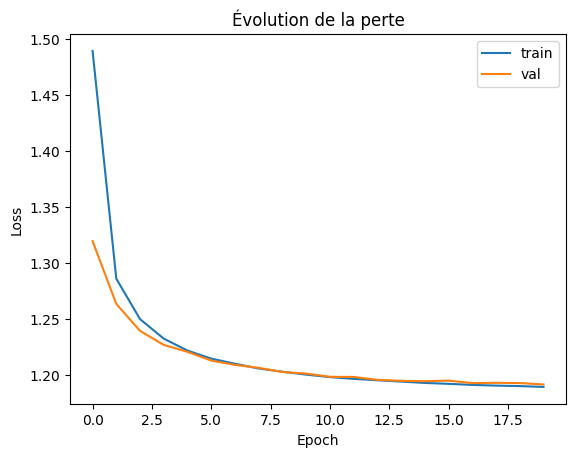

In [31]:
plt.figure()
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title("Évolution de la perte")
plt.show()

## 6. Génération de texte (échantillonnage avec température)

température :
- **faible** (0.5)  texte plus prévisible
- **élevée** (1.0–1.2)  texte plus créatif

In [32]:
@torch.no_grad()
def sample_next_token(logits_row, temperature: float = 1.0, top_k: int = None):
    if temperature <= 0:
        temperature = 1e-6
    logits = logits_row / temperature
    if top_k is not None and top_k > 0:
        v, idx = torch.topk(logits, k=min(top_k, logits.numel()))
        mask = torch.full_like(logits, float('-inf'))
        mask[idx] = v
        logits = mask
    probs = torch.softmax(logits, dim=-1)
    idx = torch.multinomial(probs, num_samples=1)
    return idx.item()

@torch.no_grad()
def generate_text(prompt: str, max_new_tokens: int = 400, temperature: float = 0.8, top_k: int = None):
    model.eval()
    input_ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    hidden = None
    generated = list(prompt)

    logits, hidden = model(input_ids, hidden)
    last_token_id = input_ids[0, -1]

    for _ in range(max_new_tokens):
        x = last_token_id.view(1, 1)
        logits, hidden = model(x, hidden)
        next_id = sample_next_token(logits[0, -1], temperature=temperature, top_k=top_k)
        generated.append(itos[next_id])
        last_token_id = torch.tensor(next_id, device=device)

    return ''.join(generated)

# Exemples de génération
print("\n=== Génération avec température 0.5 ===")
print(generate_text("Il était une fois ", max_new_tokens=200, temperature=0.5, top_k=50))

print("\n=== Génération avec température 0.8 ===")
print(generate_text("Dans le château ", max_new_tokens=200, temperature=0.8, top_k=50))

print("\n=== Génération avec température 1.2 ===")
print(generate_text("Le jeune homme ", max_new_tokens=200, temperature=1.2, top_k=50))


=== Génération avec température 0.5 ===
Il était une fois était autre, et qui se fit en conseille de leurs honneurs ont été en savant en presse de la galanterie de la maintes cette fille, le seigneur de leur combat le soleil, sans des deux chevaux, disait-il

=== Génération avec température 0.8 ===
Dans le château (Parla, qui n'empoisonner de la Citoyens; mais il n'a pas trop élevaret de ses passerez à souper: elle attendait le prieur, & les croisième et mademoiselle de Saint.--C'était à droite, et la vageuse, 

=== Génération avec température 1.2 ===
Le jeune homme (Portication; je lui fallait se suit depuis une oblig deux furent brillaient de main, et cet homme: BRUTUS. Les graves, la reine. Ceh plus aux Peaux sustaches, son reins: dit-on, l'Eu rustrate. La fic


## 7. Sauvegarde & Rechargement du modèle

Enregistrement des poids du réseau et du vocabulaire.

In [33]:
import os
import json
import torch

SAVE_DIR = 'checkpoints'
os.makedirs(SAVE_DIR, exist_ok=True)

torch.save({
    'model_state_dict': model.state_dict(),
    'config': {
        'vocab_size': vocab_size,
        'emb_dim': 128,
        'hidden_dim': 256,
        'num_layers': 2,
        'dropout': 0.2,
    }
}, os.path.join(SAVE_DIR, 'model.pth'))

with open(os.path.join(SAVE_DIR, 'vocab.json'), 'w', encoding='utf-8') as f:
    json.dump({'stoi': stoi, 'itos': itos}, f, ensure_ascii=False, indent=2)

print(f"Modèle et vocabulaire sauvegardés dans {SAVE_DIR}")

Modèle et vocabulaire sauvegardés dans checkpoints


In [34]:
# === Rechargement ===
import os, json, torch

ckpt_path  = os.path.join(SAVE_DIR, 'model.pth')
vocab_path = os.path.join(SAVE_DIR, 'vocab.json')

if os.path.isfile(ckpt_path) and os.path.isfile(vocab_path):
    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab = json.load(f)

    stoi_loaded = {k: int(v) if isinstance(v, str) and v.isdigit() else v
                   for k, v in vocab['stoi'].items()}
    itos_loaded = {int(k): v for k, v in vocab['itos'].items()}

    cfg_ckpt = torch.load(ckpt_path, map_location=device)

    state = cfg_ckpt['model_state_dict'] if 'model_state_dict' in cfg_ckpt else cfg_ckpt

    emb_weight = state['embed.weight']
    lstm_w_ih0 = state['lstm.weight_ih_l0']
    lstm_w_hh0 = state['lstm.weight_hh_l0']

    vocab_size_saved = emb_weight.shape[0]
    emb_dim          = emb_weight.shape[1]
    hidden_dim       = lstm_w_hh0.shape[1]

    layer_ids = [int(k.split('_l')[1][0]) for k in state.keys() if 'lstm.weight_ih_l' in k]
    num_layers = (max(layer_ids) + 1) if layer_ids else 1

    net_cfg = {
        'vocab_size': vocab_size_saved,
        'emb_dim': emb_dim,
        'hidden_dim': hidden_dim,
        'num_layers': num_layers,
        'dropout': cfg_ckpt.get('config', {}).get('dropout', 0.2),
    }

    print("Configuration estimée depuis les poids :")
    print(f"  emb_dim={net_cfg['emb_dim']}")
    print(f"  hidden_dim={net_cfg['hidden_dim']}")
    print(f"  num_layers={net_cfg['num_layers']}")

    reloaded = CharLSTM(
        vocab_size=net_cfg['vocab_size'],
        emb_dim=net_cfg['emb_dim'],
        hidden_dim=net_cfg['hidden_dim'],
        num_layers=net_cfg['num_layers'],
        dropout=net_cfg['dropout'],
    ).to(device)

    reloaded.load_state_dict(state, strict=True)
    reloaded.eval()
    print('Modèle rechargé avec succès.')

    def encode_loaded(s):
        return [stoi_loaded[c] for c in s if c in stoi_loaded]

    @torch.no_grad()
    def generate_with_reloaded(prompt, max_new_tokens=200, temperature=0.8, top_k=50):
        inp = torch.tensor([encode_loaded(prompt)], dtype=torch.long, device=device)
        hidden = None
        logits, hidden = reloaded(inp, hidden)
        last_id = inp[0, -1]
        out_chars = list(prompt)

        for _ in range(max_new_tokens):
            x = last_id.view(1, 1)
            logits, hidden = reloaded(x, hidden)
            nxt = sample_next_token(logits[0, -1], temperature=temperature, top_k=top_k)
            out_chars.append(itos_loaded[nxt])
            last_id = torch.tensor(nxt, device=device)

        return ''.join(out_chars)

    print('\n=== Test du modèle rechargé ===')
    print(generate_with_reloaded('Bonjour ', 150, temperature=0.8))

else:
    print('Aucun checkpoint trouvé.')


Configuration estimée depuis les poids :
  emb_dim=64
  hidden_dim=128
  num_layers=1
Modèle rechargé avec succès.

=== Test du modèle rechargé ===
Bonjour Itabout la faire habitable frémit de tirer, et qu'en qui voulut pris les affaires passer sur un moi-malin, qu'il semblait l'argent de _Diruice de Thab


In [35]:
def _gen_func(prompt, max_new_tokens=200, temperature=0.8, top_k=50):
    if 'generate_with_reloaded' in globals():
        return generate_with_reloaded(prompt, max_new_tokens=max_new_tokens, temperature=temperature, top_k=top_k)
    elif 'generate' in globals():
        return generate(prompt, max_new_tokens=max_new_tokens, temperature=temperature, top_k=top_k)
    else:
        raise NameError("Aucune fonction de génération trouvée")

test_prompts = [
    "Bonjour ",
    "Il était une fois ",
    "Paris ",
    "Les Misérables: ",
    "Chapitre ",
]

print("== Température=0.8, top_k=50 ==")
for p in test_prompts:
    out = _gen_func(p, max_new_tokens=200, temperature=0.8, top_k=50)
    print("-"*60)
    print(f"Prompt: {repr(p)}")
    print(out[:600])


== Température=0.8, top_k=50 ==
------------------------------------------------------------
Prompt: 'Bonjour '
Bonjour était dans quelques voix qui s'étaient plus des jours partoutes sur la crime instructifs; ceux-mêmes assurands qui les indigée de l'antiquité à ses deux hommes dont la raison avec des tremblement de c
------------------------------------------------------------
Prompt: 'Il était une fois '
Il était une fois tellait un parler, et j'en rentre vous en fit un nomma la bonne bonté d'être plus aux palais entendues pour combattrie qu'il eut parler par la lance qui donne dans les matins qu'il n'est pas donc assu
------------------------------------------------------------
Prompt: 'Paris '
Paris n'appercevé en sûreté de la lune, et nous arrivent une gens des Indés, pour grand ce cer ne le te peut eût un marchand blanche, le ciel dans les recevez à eux encore des mages de son témoignage, et vo
------------------------------------------------------------
Prompt: 'Les Misérables:

In [36]:
# === Balayage (température, top_k) ===
prompt_ref = "Il était une fois "
for t in [0.7, 0.9, 1.1]:
    for k in [0, 20, 50]:
        print(f"\n### temp={t}, top_k={k}")
        txt = _gen_func(prompt_ref, max_new_tokens=200, temperature=t, top_k=k)
        print(txt[:600])



### temp=0.7, top_k=0
Il était une fois était conselle dans les yeux; et pour disputer son assez que la dame. Je ne sais pas que l'ennemi de son caractère. Le désentaue. Il va du Galation donner la plus belle fut mistos pas mon car ce sont 

### temp=0.7, top_k=20
Il était une fois tences donnant dans le chemant d'arrivée dans la maison; ne voici un faire contre les hommes de la vieille avait jolie de la guerre aux chevaux. Les deux paroles aventures. Les grands expliquaient au 

### temp=0.7, top_k=50
Il était une fois fait qu'il avait bas un mieux dans le temps de voir dans le monde intime avaient juste fort ou ma grands amissement. Il en avait reçu le temps dans un faux qui ne se parade prend d'autres frères tendr

### temp=0.9, top_k=0
Il était une fois qui s'écrie, ce qu'elle admirait Théomété, brutesse: on en fut servir au près une dole, de votre famille un sauver était pas pour se mérite saver. Il ayez récompenser ni presque trouver la moral, qui 

### temp=0.9, top_k=20
Il éta

In [37]:
# === Effet de la longueur  ===
prompt_ref = "Paris "
for L in [100, 200, 400]:
    print(f"\n### max_new_tokens={L}")
    txt = _gen_func(prompt_ref, max_new_tokens=L, temperature=0.8, top_k=50)
    print(txt[:600])



### max_new_tokens=100
Paris mêle dans le cirqueurs, me grace; il n'y avait point été le petit tout paraît pas; nu moins la plus 

### max_new_tokens=200
Paris personnage! Il assassager vos esprits de la Tervait autant qu'elle attaquité dans le prix de lui pense à cette heurent avec Rome dans les pointes qui semblaient pas que des passions choses. Ce monde. 

### max_new_tokens=400
Paris courut être ce même se déclarérait. Le jour des Juifs par la terre produire donna de faveurs dans les cents villers, était le mere tort qu'on amener à la destinée fut été moins jusqu'au premier chien, et après jugèrent des bons; et j'on leur donner à moi. ANTOINE. Il trouva l'observait destinée. _Le Mourant, et nous sages la coutume à estion de rien pour sous le moine de Pococurante, aux pieds de 
